In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C7"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C7_10,28,"[DATA/TRAINING/C7/C7_10/IMG_8189.HEIC, DATA/TR..."
1,C7_11,27,"[DATA/TRAINING/C7/C7_11/IMG_8248.HEIC, DATA/TR..."
2,C7_12,25,"[DATA/TRAINING/C7/C7_12/IMG_8280.HEIC, DATA/TR..."
3,C7_13,25,"[DATA/TRAINING/C7/C7_13/IMG_8311.HEIC, DATA/TR..."
4,C7_14,25,"[DATA/TRAINING/C7/C7_14/IMG_8406.HEIC, DATA/TR..."
5,C7_15,25,"[DATA/TRAINING/C7/C7_15/IMG_8343.HEIC, DATA/TR..."
6,C7_16,27,"[DATA/TRAINING/C7/C7_16/IMG_8375.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_8380.HEIC')

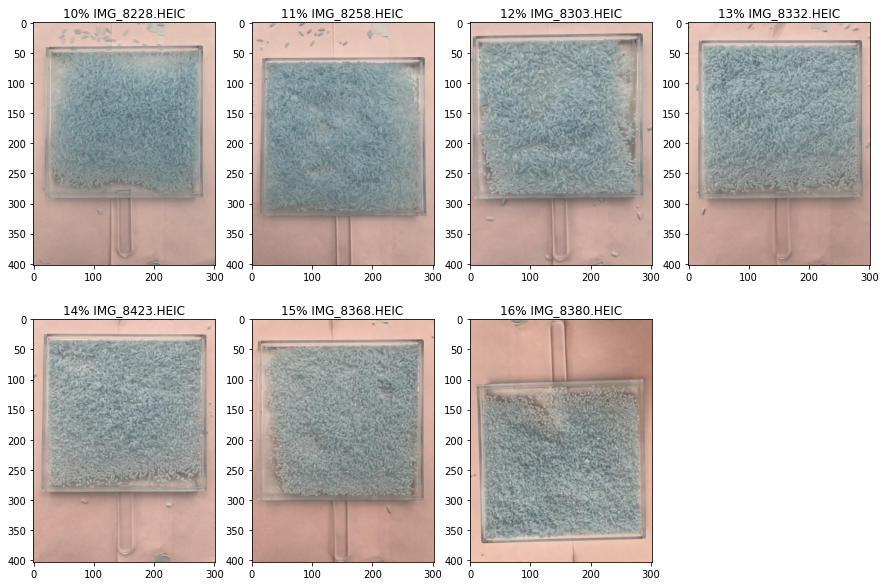

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [152]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [153]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.001875,47.398783,0.935225,365.874649,0.323948,331.832116,1416.099811,7.018133,10.191727,0.000552,...,0.000424,4.045750,-0.269326,0.980760,3,120,90,3,IMG_8189.HEIC,10
1,0.001266,50.800843,0.947296,481.944850,0.303263,314.980618,1876.978557,7.226424,10.495500,0.000508,...,0.000381,4.162039,-0.265779,0.981909,3,120,90,3,IMG_8190.HEIC,10
2,0.001231,55.481461,0.949751,552.061849,0.303432,318.035955,2152.765936,7.286053,10.592934,0.000494,...,0.000371,4.208221,-0.269068,0.983181,3,120,90,3,IMG_8193.HEIC,10
3,0.001070,70.887547,0.921047,448.920851,0.284054,315.838296,1724.795856,7.162190,10.636508,0.000447,...,0.000323,4.320594,-0.233932,0.972253,3,120,90,3,IMG_8194.HEIC,10
4,0.001784,46.622753,0.934224,354.403171,0.321088,333.322753,1370.989932,6.944537,10.153270,0.000525,...,0.000390,4.077828,-0.248704,0.974145,3,120,90,3,IMG_8199.HEIC,10
5,0.001057,66.267790,0.925380,444.036557,0.282124,319.937079,1709.878438,7.221453,10.664642,0.000449,...,0.000329,4.304940,-0.245284,0.976662,3,120,90,3,IMG_8206.HEIC,10
6,0.001081,66.539794,0.913505,384.645702,0.284447,322.911517,1472.043013,7.195169,10.589276,0.000441,...,0.000313,4.339361,-0.246239,0.976677,3,120,90,3,IMG_8210.HEIC,10
7,0.001244,73.243633,0.901040,370.068332,0.267824,329.697566,1407.029694,7.040076,10.547882,0.000400,...,0.000282,4.447991,-0.213012,0.962121,3,120,90,3,IMG_8211.HEIC,10
8,0.001024,94.103558,0.869182,359.674750,0.253742,315.079026,1344.595440,7.001871,10.706122,0.000364,...,0.000256,4.584490,-0.192843,0.951220,3,120,90,3,IMG_8215.HEIC,10
9,0.001086,90.492790,0.876126,365.260731,0.263853,328.587921,1370.550135,7.155839,10.774845,0.000378,...,0.000271,4.533607,-0.214440,0.964517,3,120,90,3,IMG_8216.HEIC,10


# Classification

In [154]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [155]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [156]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [157]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [158]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [159]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.642857,0.571429,0.605042,HRLK,C7,RF_C,3,120,90,3
1,2,0.526316,0.528571,0.500000,0.513889,HRLK,C7,RF_C,3,120,90,3
2,3,0.555556,0.583333,0.571429,0.577320,HRLK,C7,RF_C,3,120,90,3
3,4,0.722222,0.823810,0.761905,0.791649,HRLK,C7,RF_C,3,120,90,3
4,5,0.555556,0.580952,0.595238,0.588008,HRLK,C7,RF_C,3,120,90,3
5,6,0.555556,0.628571,0.523810,0.571429,HRLK,C7,RF_C,3,120,90,3
6,7,0.611111,0.742857,0.595238,0.660905,HRLK,C7,RF_C,3,120,90,3
7,8,0.500000,0.452381,0.476190,0.463980,HRLK,C7,RF_C,3,120,90,3
8,9,0.500000,0.511905,0.476190,0.493402,HRLK,C7,RF_C,3,120,90,3
9,10,0.611111,0.723810,0.595238,0.653258,HRLK,C7,RF_C,3,120,90,3


In [160]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C7,RF_C,0.571637,0.566667,0.591888,0.621905


### MLP Classifier

In [161]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [162]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [163]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.684211,0.795238,0.642857,0.710974,HRLK,C7,MLP_C,3,120,90,3
1,2,0.736842,0.750000,0.714286,0.731707,HRLK,C7,MLP_C,3,120,90,3
2,3,0.722222,0.800000,0.738095,0.767802,HRLK,C7,MLP_C,3,120,90,3
3,4,0.722222,0.800000,0.738095,0.767802,HRLK,C7,MLP_C,3,120,90,3
4,5,0.888889,0.928571,0.904762,0.916512,HRLK,C7,MLP_C,3,120,90,3
5,6,0.611111,0.654762,0.595238,0.623583,HRLK,C7,MLP_C,3,120,90,3
6,7,0.611111,0.690476,0.595238,0.639330,HRLK,C7,MLP_C,3,120,90,3
7,8,0.722222,0.776190,0.738095,0.756664,HRLK,C7,MLP_C,3,120,90,3
8,9,0.666667,0.678571,0.595238,0.634179,HRLK,C7,MLP_C,3,120,90,3
9,10,0.777778,0.821429,0.761905,0.790548,HRLK,C7,MLP_C,3,120,90,3


In [164]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C7,MLP_C,0.714327,0.702381,0.73391,0.769524


### XGBoost Classifier

In [165]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [166]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.690476,0.571429,0.625337,HRLK,C7,XGB_C,3,120,90,3
1,2,0.473684,0.557143,0.500000,0.527027,HRLK,C7,XGB_C,3,120,90,3
2,3,0.500000,0.647619,0.547619,0.593436,HRLK,C7,XGB_C,3,120,90,3
3,4,0.722222,0.785714,0.738095,0.761161,HRLK,C7,XGB_C,3,120,90,3
4,5,0.500000,0.509524,0.547619,0.527885,HRLK,C7,XGB_C,3,120,90,3
5,6,0.777778,0.809524,0.809524,0.809524,HRLK,C7,XGB_C,3,120,90,3
6,7,0.611111,0.704762,0.595238,0.645386,HRLK,C7,XGB_C,3,120,90,3
7,8,0.722222,0.788095,0.714286,0.749377,HRLK,C7,XGB_C,3,120,90,3
8,9,0.500000,0.571429,0.476190,0.519481,HRLK,C7,XGB_C,3,120,90,3
9,10,0.722222,0.814286,0.690476,0.747288,HRLK,C7,XGB_C,3,120,90,3


In [167]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C7,XGB_C,0.610819,0.619048,0.65059,0.687857


# External validation

In [168]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C7_10,5,"[DATA/TEST/C7/C7_10/IMG_8188.HEIC, DATA/TEST/C..."
1,C7_11,5,"[DATA/TEST/C7/C7_11/IMG_8249.HEIC, DATA/TEST/C..."
2,C7_12,5,"[DATA/TEST/C7/C7_12/IMG_8279.HEIC, DATA/TEST/C..."
3,C7_13,5,"[DATA/TEST/C7/C7_13/IMG_8316.HEIC, DATA/TEST/C..."
4,C7_14,5,"[DATA/TEST/C7/C7_14/IMG_8411.HEIC, DATA/TEST/C..."
5,C7_15,5,"[DATA/TEST/C7/C7_15/IMG_8344.HEIC, DATA/TEST/C..."
6,C7_16,5,"[DATA/TEST/C7/C7_16/IMG_8377.HEIC, DATA/TEST/C..."


In [169]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [170]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [171]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.001901,47.117603,0.938842,385.212008,0.323403,328.686891,1493.730427,7.024425,10.206267,0.000541,...,0.000413,4.081072,-0.263040,0.979274,3,120,90,3,IMG_8188.HEIC,10
1,0.001501,55.806086,0.939371,460.228276,0.291959,314.839232,1785.107019,7.095640,10.424436,0.000478,...,0.000361,4.203086,-0.253495,0.977556,3,120,90,3,IMG_8198.HEIC,10
2,0.001289,59.301966,0.923337,386.770142,0.296993,313.303464,1487.778602,6.973174,10.339337,0.000483,...,0.000357,4.231376,-0.236452,0.970936,3,120,90,3,IMG_8202.HEIC,10
3,0.001159,72.199345,0.911776,409.184293,0.278405,327.416760,1564.537828,7.135346,10.626312,0.000413,...,0.000310,4.364671,-0.235845,0.972634,3,120,90,3,IMG_8203.HEIC,10
4,0.001620,57.051498,0.930731,411.808974,0.317548,327.007678,1590.184398,7.083239,10.281195,0.000532,...,0.000387,4.185967,-0.262790,0.979747,3,120,90,3,IMG_8207.HEIC,10
0,0.001504,52.365824,0.945215,477.917415,0.318076,319.748783,1859.303837,7.025854,10.251389,0.000517,...,0.000353,4.222593,-0.247327,0.974921,3,120,90,3,IMG_8249.HEIC,11
1,0.001494,66.173783,0.930622,476.909097,0.303990,313.309551,1841.462605,7.054434,10.406962,0.000485,...,0.000354,4.255678,-0.237885,0.972313,3,120,90,3,IMG_8251.HEIC,11
2,0.001403,72.186704,0.920891,456.249262,0.301028,313.154682,1752.810343,6.984082,10.360456,0.000477,...,0.000339,4.279774,-0.232510,0.969619,3,120,90,3,IMG_8252.HEIC,11
3,0.001174,66.522940,0.930858,481.063040,0.297343,320.382303,1857.729219,7.240174,10.637141,0.000454,...,0.000330,4.256643,-0.254381,0.979347,3,120,90,3,IMG_8264.HEIC,11
4,0.001121,62.411330,0.927457,430.165313,0.299374,316.986985,1658.249924,7.200846,10.556320,0.000491,...,0.000349,4.264714,-0.244893,0.976218,3,120,90,3,IMG_8272.HEIC,11


In [172]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [173]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [174]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [175]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [176]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.75      0.60      0.67         5
     Class 1       0.71      1.00      0.83         5
     Class 2       0.80      0.80      0.80         5
     Class 3       1.00      0.40      0.57         5
     Class 4       0.67      0.40      0.50         5
     Class 5       0.29      0.40      0.33         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.66        35
   macro avg       0.70      0.66      0.65        35
weighted avg       0.70      0.66      0.65        35



## MLP

In [177]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.71      1.00      0.83         5
     Class 1       0.75      0.60      0.67         5
     Class 2       1.00      0.60      0.75         5
     Class 3       0.75      0.60      0.67         5
     Class 4       0.75      0.60      0.67         5
     Class 5       0.40      0.40      0.40         5
     Class 6       0.62      1.00      0.77         5

    accuracy                           0.69        35
   macro avg       0.71      0.69      0.68        35
weighted avg       0.71      0.69      0.68        35



## XGBC

In [179]:
y_pred = modelXGBC.predict(X_test_scale) 

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.75      0.60      0.67         5
     Class 1       0.57      0.80      0.67         5
     Class 2       1.00      1.00      1.00         5
     Class 3       0.75      0.60      0.67         5
     Class 4       0.60      0.60      0.60         5
     Class 5       0.43      0.60      0.50         5
     Class 6       1.00      0.60      0.75         5

    accuracy                           0.69        35
   macro avg       0.73      0.69      0.69        35
weighted avg       0.73      0.69      0.69        35

